# Etiquetas por fuentes externas y puntaje de análogo

<a href="https://colab.research.google.com/github/Niettzche/spaceapps-2026/blob/main/ciencia_datos/03_etiquetas_por_fuentes.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

A 200 m por píxel no se puede decidir a ojo si una detección es cráter. Así que las etiquetas de la Tierra salen de **fuentes citables**:

- **Cráteres volcánicos:** catálogo `crateres_conocidos_mx.csv` (Smithsonian GVP y artículos; cada fila trae su URL). Una detección es "volcánico" si está a menos de 2.5 km de un cráter del catálogo.
- **Minas:** canteras de OpenStreetMap (`landuse=quarry`). Una detección es "mina" si está a menos de 2 km de una.
- Todo lo demás queda **sin confirmar** y no se usa para entrenar.

Luego:
1. ¿Cuántos cráteres conocidos encuentra el detector? (validación del detector con verdad de campo)
2. Modelo de tres clases con Tierra = solo cráteres volcánicos del catálogo.
3. **Puntaje principal:** modelo Luna contra Marte (datos limpios) y distancia a la nube Luna+Marte, aplicado a todas las detecciones de México, sin depender de etiquetas terrestres.

Datos: `hoyas_mexico.csv` (las 5,208 depresiones de la celda 07, exportadas por `analisis/14_exportar_hoyas.py`), `hoyas_referencia.csv` y el catálogo.

In [1]:
import subprocess
from pathlib import Path
REPO, RUTA = "Niettzche/spaceapps-2026", "ciencia_datos/datos"
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / RUTA / "hoyas_mexico.csv").exists()), None)
if RAIZ is None:
    try:
        from google.colab import userdata
        url = f"https://{userdata.get('GITHUB_TOKEN')}@github.com/{REPO}.git"
    except Exception:
        url = f"https://github.com/{REPO}.git"
    subprocess.run(["git", "clone", "--depth", "1", url, "/content/spaceapps-2026"], check=True)
    RAIZ = Path("/content/spaceapps-2026")
DATOS, SALIDA = RAIZ / RUTA, RAIZ / "ciencia_datos" / "salidas"
SALIDA.mkdir(parents=True, exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score
from sklearn.covariance import MinCovDet

COLORES = {"Luna": "#8a8f98", "Marte": "#b5532f", "Tierra": "#1f6f78", "volcánico": "#1f6f78", "mina": "#c7921a", "sin confirmar": "#b8bcbf"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
RADIO_KM, MINA_KM = 2.5, 2.0

hoyas = pd.read_csv(DATOS / "hoyas_mexico.csv")
ref = pd.read_csv(DATOS / "hoyas_referencia.csv")
cat = pd.read_csv(DATOS / "crateres_conocidos_mx.csv")
print(f"Depresiones en México: {len(hoyas):,} (tipo cráter: {int(hoyas.crater.sum())}) | Catálogo: {len(cat)} cráteres")
print(cat.groupby(["confianza_coord"]).size().to_string())

Depresiones en México: 5,208 (tipo cráter: 668) | Catálogo: 70 cráteres
confianza_coord
alta     24
baja     13
media    29


## 1. Cotejo del catálogo con las detecciones

Para cada cráter del catálogo con coordenadas, la depresión más cercana. Si está a menos de 2.5 km, el detector lo encontró. Después vemos si además pasa el filtro "tipo cráter" (0.6–10 km, ≥ 20 m, circularidad ≥ 0.6).

Razones esperables para no encontrarlo: es más chico que 0.6 km (el detector no lo ve), tiene lago (el modelo de elevación ve el espejo de agua, no el fondo) o es menos hondo que 20 m.

In [2]:
def dist_km(lat1, lon1, lat2, lon2):
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

c = cat.dropna(subset=["lat", "lon"]).reset_index(drop=True)
hl, ho = hoyas.lat.to_numpy(), hoyas.lon.to_numpy()
idx, dmin = [], []
for la, lo in zip(c.lat, c.lon):
    d = dist_km(la, lo, hl, ho); k = int(np.argmin(d)); idx.append(k); dmin.append(d[k])
c["hid"] = hoyas.hid.to_numpy()[idx]; c["a_km"] = np.round(dmin, 2)
c["detectado"] = c.a_km <= RADIO_KM
c = c.merge(hoyas[["hid", "diam_km", "prof_m", "prof_diam", "circ", "borde_m", "crater", "ndvi_p90", "km_mina"]], on="hid", how="left")
c["pasa_filtro"] = c.detectado & c.crater.fillna(False).astype(bool)
# una depresión no debe contar dos veces: si dos cráteres del catálogo caen en la misma, se queda el más cercano
dup = c[c.detectado].sort_values("a_km").duplicated("hid")
c.loc[dup[dup].index, ["detectado", "pasa_filtro"]] = False

def razon(r):
    if r.pasa_filtro: return "detectado y pasa el filtro"
    if r.detectado: return "detectado, no pasa el filtro"
    if pd.notna(r.diam_km_aprox) and r.diam_km_aprox < 0.6: return "no detectado: más chico que 0.6 km"
    if str(r.get("lago", "")).lower().startswith(("si", "sí", "estacional")): return "no detectado: con lago"
    return "no detectado: otra razón"
c["resultado"] = c.apply(razon, axis=1)
print(c.resultado.value_counts().to_string())
en_rango = c.diam_km_aprox.between(0.6, 10) | c.diam_km_aprox.isna()
print(f"\nEn el rango de tamaño del detector (0.6–10 km o sin dato): {int(en_rango.sum())}; "
      f"detectados {c[en_rango].detectado.mean():.0%}, pasan el filtro {c[en_rango].pasa_filtro.mean():.0%}")
cols = ["nombre", "tipo", "estado", "diam_km_aprox", "a_km", "diam_km", "prof_m", "circ", "borde_m", "resultado"]
c[cols].sort_values(["resultado", "nombre"]).round(2)

resultado
no detectado: otra razón              22
detectado y pasa el filtro            20
no detectado: con lago                15
detectado, no pasa el filtro           6
no detectado: más chico que 0.6 km     3

En el rango de tamaño del detector (0.6–10 km o sin dato): 62; detectados 40%, pasan el filtro 32%


,nombre,tipo,estado,diam_km_aprox,a_km,diam_km,prof_m,circ,borde_m,resultado
26,Alberca de Teremendo (= Alberca de G...,maar,Michoacán,0.95,0.06,0.68,75.62,0.72,5.29,detectado y pasa el filtro
40,Aljojuca,maar,Puebla,1.60,0.33,0.98,83.46,0.67,-1.60,detectado y pasa el filtro
6,Celaya (Volcán Los Vidrios),maar,Sonora,1.04,0.01,0.98,51.16,0.97,4.06,detectado y pasa el filtro
8,Cerro Colorado,cono_toba,Sonora,0.96,0.33,0.64,34.01,1.00,23.52,detectado y pasa el filtro
0,Cráter El Elegante,maar,Sonora,1.50,0.21,1.44,201.14,0.82,19.30,detectado y pasa el filtro
...,...,...,...,...,...,...,...,...,...,...
65,San Juan (caldera de la cima),caldera,Nayarit,2.00,13.86,1.01,30.44,0.40,-23.01,no detectado: otra razón
23,San Manuel,maar,Guanajuato,1.06,2.62,1.37,104.54,0.74,23.22,no detectado: otra razón
49,San Martín Tuxtla (cráter de cima),crater_cima,Veracruz,1.00,9.25,0.71,22.81,0.75,-29.60,no detectado: otra razón
24,Santa Rosa (anillo de toba),anillo_toba,Guanajuato,2.10,1.86,1.37,104.54,0.74,23.22,no detectado: otra razón


## 2. Etiquetas desde fuentes para todas las depresiones

In [3]:
volc = set(c.loc[c.detectado, "hid"])
hoyas["fuente"] = np.where(hoyas.hid.isin(volc), "volcánico", np.where(hoyas.km_mina <= MINA_KM, "mina", "sin confirmar"))
hoyas["entorno"] = pd.cut(hoyas.ndvi_p90, [0, 0.35, 0.7, 1], labels=["árido", "intermedio", "húmedo"])
print("Todas las depresiones:"); print(pd.crosstab(hoyas.fuente, hoyas.crater.map({True: "tipo cráter", False: "otras"})).to_string())
print("\nSolo tipo cráter, por entorno:"); print(pd.crosstab(hoyas[hoyas.crater].fuente, hoyas[hoyas.crater].entorno).to_string())

Todas las depresiones:
crater         otras  tipo cráter
fuente                           
mina              29           17
sin confirmar   4505          631
volcánico          6           20

Solo tipo cráter, por entorno:
entorno        árido  intermedio  húmedo
fuente                                  
mina              10           2       5
sin confirmar     30         142     459
volcánico          6          12       2


## 3. Modelo de tres clases con Tierra = cráteres volcánicos del catálogo

Misma receta que los notebooks anteriores: variables de forma comparables entre cuerpos, pesos por clase, validación por grupos espaciales repetida 10 veces. Comparamos tres definiciones de "Tierra".

In [4]:
F = ["log_diam", "prof_diam", "borde_rel", "relleno", "aspecto"]
def preparar(d):
    d = d.copy(); d["log_diam"] = np.log10(d.diam_km); d["borde_rel"] = d.borde_m / (d.diam_km * 1000); return d
r = preparar(ref[ref.crater])
r["grupo"] = r.cuerpo + "|" + r.sitio + "|" + (r.i // 250).astype(int).astype(str) + "_" + (r.j // 250).astype(int).astype(str)
h = preparar(hoyas); h["cuerpo"] = "Tierra"; h["grupo"] = "T|" + h.br.astype(str) + "_" + h.bc.astype(str)
COLS = F + ["cuerpo", "grupo"]

def evaluar(datos, modelo, feats=F, reps=10):
    X, y, g = datos[feats].to_numpy(float), datos.cuerpo.to_numpy(object), datos.grupo.to_numpy(object)
    clases = sorted(set(y)); ba, rec = [], {k: [] for k in clases}
    for s in range(reps):
        pred = np.empty(len(y), object)
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, g):
            modelo.fit(X[tr], y[tr]); pred[te] = modelo.predict(X[te])
        ba.append(balanced_accuracy_score(y, pred))
        for k in clases: rec[k].append((pred[y == k] == k).mean())
    return {"exactitud balanceada": f"{np.mean(ba):.0%} ± {np.std(ba):.0%}", **{f"acierto {k}": f"{np.mean(v):.0%}" for k, v in rec.items()}}

logistica = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000))
arbol = lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, class_weight="balanced", random_state=0)

defs = {
    "47 áridas (notebook 01)": h.crater & (h.ndvi_p90 < 0.35),
    "volcánicos del catálogo": h.crater & (h.fuente == "volcánico"),
    "volcánicos + minas (fuentes)": h.crater & h.fuente.isin(["volcánico", "mina"]),
}
filas = []
for nombre, sel in defs.items():
    datos = pd.concat([r[COLS], h.loc[sel, COLS]], ignore_index=True)
    n = int(sel.sum())
    if n < 5 or datos[datos.cuerpo == "Tierra"].grupo.nunique() < 5:
        filas.append({"Tierra =": nombre, "n Tierra": n, "exactitud balanceada": "muy pocos casos"}); continue
    for mn, m in [("logística", logistica()), ("árbol", arbol())]:
        filas.append({"Tierra =": nombre, "n Tierra": n, "modelo": mn, **evaluar(datos, m)})
pd.DataFrame(filas)

,Tierra =,n Tierra,modelo,exactitud balanceada,acierto Luna,acierto Marte,acierto Tierra
0,47 áridas (notebook 01),46,logística,58% ± 1%,53%,69%,52%
1,47 áridas (notebook 01),46,árbol,54% ± 2%,60%,64%,38%
2,volcánicos del catálogo,20,logística,60% ± 1%,56%,74%,51%
3,volcánicos del catálogo,20,árbol,59% ± 1%,67%,67%,42%
4,volcánicos + minas (fuentes),37,logística,59% ± 1%,50%,77%,50%
5,volcánicos + minas (fuentes),37,árbol,59% ± 1%,50%,73%,55%


In [5]:
# Reglas del árbol con la Tierra mejor etiquetada
sel = defs["volcánicos del catálogo"]
if sel.sum() >= 5:
    datos = pd.concat([r[COLS], h.loc[sel, COLS]], ignore_index=True)
    t = arbol().fit(datos[F].to_numpy(float), datos.cuerpo.to_numpy(object))
    print(export_text(t, feature_names=F, decimals=3))

|--- borde_rel <= -0.002
|   |--- prof_diam <= 0.038
|   |   |--- borde_rel <= -0.026
|   |   |   |--- class: Tierra
|   |   |--- borde_rel >  -0.026
|   |   |   |--- class: Marte
|   |--- prof_diam >  0.038
|   |   |--- borde_rel <= -0.009
|   |   |   |--- class: Luna
|   |   |--- borde_rel >  -0.009
|   |   |   |--- class: Luna
|--- borde_rel >  -0.002
|   |--- log_diam <= 0.205
|   |   |--- borde_rel <= 0.017
|   |   |   |--- class: Tierra
|   |   |--- borde_rel >  0.017
|   |   |   |--- class: Tierra
|   |--- log_diam >  0.205
|   |   |--- prof_diam <= 0.085
|   |   |   |--- class: Marte
|   |   |--- prof_diam >  0.085
|   |   |   |--- class: Luna



## 4. Puntaje principal: Luna contra Marte, y México como invitado

Entrenado solo con datos limpios (Luna y Marte). Para cada detección tipo cráter de México:
- `P_Luna`: probabilidad de que el modelo la tome por lunar (1 − P_Luna = marciana).
- `dist`: distancia de Mahalanobis robusta a la nube Luna+Marte; `dentro_95` si cae dentro del 95 % de esa nube.

Si `dentro_95` es verdadero, en forma es un análogo plausible. Si es falso, la analogía se rompe por forma: hay que decir por qué (más hondo, más plano, borde distinto).

In [6]:
FD = ["log_diam", "prof_diam", "borde_rel"]
# Marte: 8 sitios. Elysium y Utopia se excluyen (14 y 9 cráteres, llanuras muy lisas, posible DEM solo MOLA)
lm = r[~r.sitio.str.contains("Elysium|Utopia")]
print(lm.groupby(["cuerpo", "sitio"]).size().to_string())
# ¿Generaliza a un sitio de Marte que no vio? Se entrena sin ese sitio y se prueba en él
for s in lm[lm.cuerpo == "Marte"].sitio.unique():
    tr, te = lm[lm.sitio != s], lm[lm.sitio == s]
    mm = logistica().fit(tr[FD].to_numpy(float), tr.cuerpo.to_numpy(object))
    print(f"  sitio de Marte nunca visto: {s:24s} acierto {(mm.predict(te[FD].to_numpy(float)) == 'Marte').mean():.0%}")
modelo_lm = logistica().fit(lm[FD].to_numpy(float), lm.cuerpo.to_numpy(object))
print("Luna contra Marte (validación por grupos):", evaluar(lm[FD + ["cuerpo", "grupo"]], logistica(), feats=FD, reps=5))
esc = StandardScaler().fit(lm[FD]); mcd = MinCovDet(random_state=0).fit(esc.transform(lm[FD]))
corte = np.quantile(mcd.mahalanobis(esc.transform(lm[FD])), 0.95)

mxc = h[h.crater].copy()
mxc["P_Luna"] = modelo_lm.predict_proba(mxc[FD].to_numpy(float))[:, list(modelo_lm.classes_).index("Luna")]
mxc["dist"] = mcd.mahalanobis(esc.transform(mxc[FD]))
mxc["dentro_95"] = mxc.dist <= corte
nom = c[c.detectado].set_index("hid").nombre
mxc["nombre"] = mxc.hid.map(nom)
res = mxc.groupby("fuente").agg(n=("P_Luna", "size"), P_Luna_media=("P_Luna", "mean"), dentro_95=("dentro_95", "mean")).round(2)
print(res.to_string())
cols = ["hid", "cid", "nombre", "fuente", "lat", "lon", "diam_km", "prof_m", "prof_diam", "borde_m", "ndvi_p90", "P_Luna", "dist", "dentro_95"]
mxc[cols].round(4).to_csv(SALIDA / "puntaje_luna_marte_mexico.csv", index=False)
print("\nCráteres volcánicos del catálogo:")
mxc[mxc.fuente == "volcánico"][["nombre", "diam_km", "prof_diam", "borde_m", "P_Luna", "dist", "dentro_95"]].sort_values("P_Luna", ascending=False).round(3)

cuerpo  sitio                  
Luna    Anillo 80-85°S             3232
        Polo sur (85-90°S)         1056
Marte   Chryse (Viking 1)            23
        Cráter Gale                  90
        Cráter Jezero               104
        Gusev (Spirit)              101
        Meridiani (Opportunity)     165
        Oxia Planum                  90
  sitio de Marte nunca visto: Cráter Jezero            acierto 82%
  sitio de Marte nunca visto: Cráter Gale              acierto 70%
  sitio de Marte nunca visto: Oxia Planum              acierto 84%
  sitio de Marte nunca visto: Meridiani (Opportunity)  acierto 92%
  sitio de Marte nunca visto: Gusev (Spirit)           acierto 75%
  sitio de Marte nunca visto: Chryse (Viking 1)        acierto 91%


Luna contra Marte (validación por grupos): {'exactitud balanceada': '78% ± 0%', 'acierto Luna': '73%', 'acierto Marte': '82%'}


                 n  P_Luna_media  dentro_95
fuente                                     
mina            17          0.71       0.76
sin confirmar  631          0.57       0.93
volcánico       20          0.57       0.90

Cráteres volcánicos del catálogo:


,nombre,diam_km,prof_diam,borde_m,P_Luna,dist,dentro_95
58,Sykes (Cráter Grande / Volcán Romo),0.903,0.197,34.244,0.998,38.718,False
56,Cráter El Elegante,1.445,0.139,19.300,0.972,15.907,True
3132,Alberca de Teremendo (= Alberca de G...,0.677,0.112,5.288,0.945,7.042,True
3232,Aljojuca,0.984,0.085,-1.598,0.830,2.082,True
2607,Hoya de Álvarez (Hoya de Flores),1.409,0.087,30.653,0.791,5.893,True
2606,Hoya de Cíntora,1.531,0.078,-13.538,0.749,2.797,True
2609,Hoya Rincón de Parangueo,1.373,0.076,23.218,0.716,4.000,True
4117,El Chichón (cráter 1982),0.714,0.076,96.744,0.617,40.322,False
55,MacDougal (Cráter Verdugo),1.596,0.063,1.425,0.599,2.598,True
3242,Tepexitl,0.814,0.056,18.144,0.577,3.137,True


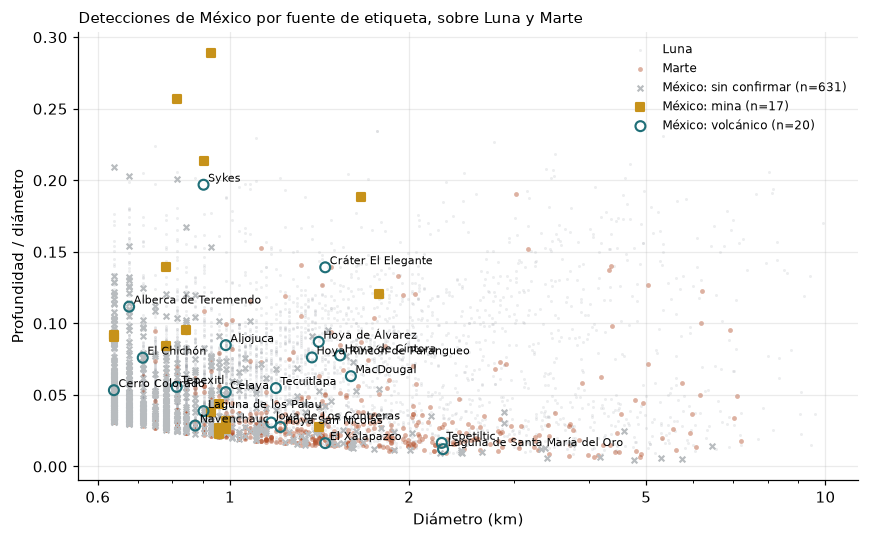

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for k, s, a in [("Luna", 4, .15), ("Marte", 10, .45)]:
    d = lm[lm.cuerpo == k]; ax.scatter(d.diam_km, d.prof_diam, s=s, alpha=a, color=COLORES[k], lw=0, label=k)
for f, mk, s in [("sin confirmar", "x", 14), ("mina", "s", 30), ("volcánico", "o", 42)]:
    d = mxc[mxc.fuente == f]
    ax.scatter(d.diam_km, d.prof_diam, s=s, marker=mk, color=COLORES[f] if f != "volcánico" else "none",
               edgecolors=COLORES[f] if f == "volcánico" else None, lw=1.4, label=f"México: {f} (n={len(d)})", zorder=3)
for _, p in mxc[mxc.nombre.notna()].iterrows():
    ax.annotate(str(p.nombre).split(" (")[0], (p.diam_km, p.prof_diam), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xticks([0.6, 1, 2, 5, 10]); ax.set_xticklabels(["0.6", "1", "2", "5", "10"])
ax.set_xlabel("Diámetro (km)"); ax.set_ylabel("Profundidad / diámetro"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Detecciones de México por fuente de etiqueta, sobre Luna y Marte", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "fuentes_sobre_luna_marte.png", bbox_inches="tight"); plt.show()

## 4b. Validación con cráteres de impacto de la Tierra

Si la métrica tiene sentido, los cráteres de impacto terrestres bien conservados deberían caer dentro de la nube Luna+Marte. Son 10 impactos simples medidos con el mismo detector sobre Copernicus GLO-30 (`analisis/15_referencias_extra.py`). Brent no se detecta (erosionado, con bosque y lagos) y Xiuyan se excluye porque la depresión detectada no coincide en tamaño. Las coordenadas son aproximadas, del Earth Impact Database.

In [8]:
imp = preparar(pd.read_csv(DATOS / "impactos_tierra.csv"))
imp = imp[imp.detectado.astype(bool) & (imp.nombre != "Xiuyan")].copy()
imp["P_Luna"] = modelo_lm.predict_proba(imp[FD].to_numpy(float))[:, list(modelo_lm.classes_).index("Luna")]
imp["dist"] = mcd.mahalanobis(esc.transform(imp[FD])); imp["dentro_95"] = imp.dist <= corte
print(f"Impactos terrestres dentro de la nube Luna+Marte: {int(imp.dentro_95.sum())} de {len(imp)}")
comp = pd.concat([imp.assign(grupo_val="impacto (Tierra)")[["nombre", "grupo_val", "diam_km", "prof_diam", "borde_m", "P_Luna", "dist", "dentro_95"]],
                  mxc[mxc.fuente == "mina"].nlargest(4, "prof_diam").assign(grupo_val="mina (México)", nombre=lambda d: d.cid)[["nombre", "grupo_val", "diam_km", "prof_diam", "borde_m", "P_Luna", "dist", "dentro_95"]]])
comp.sort_values("P_Luna", ascending=False).round(3)

Impactos terrestres dentro de la nube Luna+Marte: 8 de 8


,nombre,grupo_val,diam_km,prof_diam,borde_m,P_Luna,dist,dentro_95
2208,MX0207,mina (México),0.930,0.289,-11.405,1.000,91.490,False
832,MX0085,mina (México),0.814,0.257,-4.446,1.000,67.665,False
829,MX0084,mina (México),0.903,0.214,6.930,0.999,42.960,False
1600,MX0155,mina (México),1.658,0.188,-13.566,0.997,34.258,False
0,Meteor Crater,impacto (Tierra),1.058,0.126,21.927,0.958,11.437,True
5,Tswaing,impacto (Tierra),0.903,0.076,18.613,0.754,3.420,True
1,Lonar,impacto (Tierra),1.805,0.052,12.447,0.462,3.728,True
2,Wolfe Creek,impacto (Tierra),0.782,0.034,9.078,0.379,2.846,True
6,Roter Kamm,impacto (Tierra),1.820,0.035,34.027,0.274,5.332,True
3,Tenoumer,impacto (Tierra),1.627,0.024,28.193,0.209,4.990,True


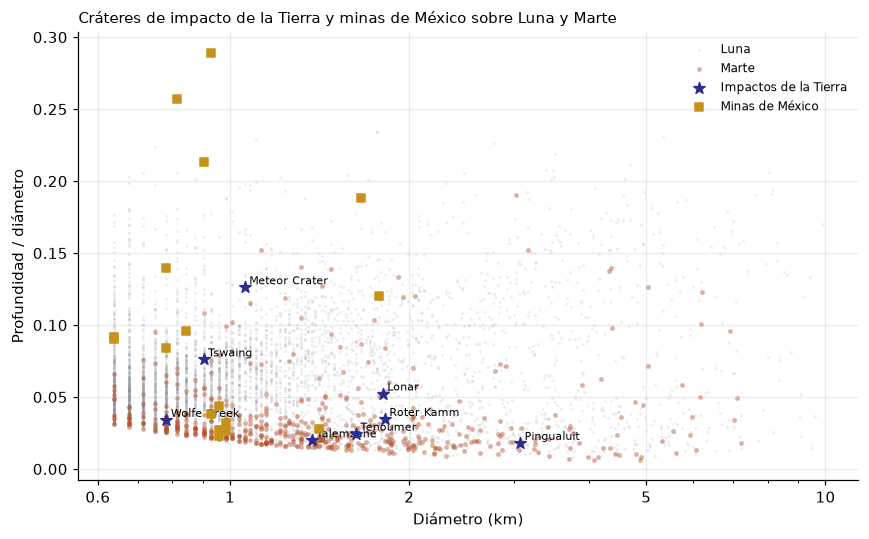

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for k, s_, a in [("Luna", 4, .15), ("Marte", 10, .45)]:
    d = lm[lm.cuerpo == k]; ax.scatter(d.diam_km, d.prof_diam, s=s_, alpha=a, color=COLORES[k], lw=0, label=k)
ax.scatter(imp.diam_km, imp.prof_diam, s=60, marker="*", color="#2a2f8f", label="Impactos de la Tierra", zorder=4)
for _, p in imp.iterrows():
    ax.annotate(p.nombre, (p.diam_km, p.prof_diam), fontsize=7, xytext=(3, 2), textcoords="offset points")
mi = mxc[mxc.fuente == "mina"]
ax.scatter(mi.diam_km, mi.prof_diam, s=30, marker="s", color=COLORES["mina"], label="Minas de México", zorder=3)
ax.set_xscale("log"); ax.set_xticks([0.6, 1, 2, 5, 10]); ax.set_xticklabels(["0.6", "1", "2", "5", "10"])
ax.set_xlabel("Diámetro (km)"); ax.set_ylabel("Profundidad / diámetro"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Cráteres de impacto de la Tierra y minas de México sobre Luna y Marte", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(SALIDA / "impactos_y_minas.png", bbox_inches="tight"); plt.show()

## 5. Lectura

**Catálogo:** 70 cráteres volcánicos de México con fuente (GVP, artículos), 66 con coordenadas. Cada coordenada se probó contra SRTM de 30 m (ver la columna `notas`).

**El detector frente a cráteres conocidos.** De los 62 cráteres del catálogo dentro del rango del detector (0.6–10 km, o sin diámetro reportado), encuentra el 40 % y el 32 % pasa el filtro "tipo cráter". Lo que no encuentra tiene causas claras:
- **15 con lago:** el modelo de elevación ve el espejo de agua, no el fondo. Es un límite del método, no del cráter.
- **3 más chicos que 0.6 km.**
- **22 por otras razones:** islas fuera del barrido, coordenadas desplazadas 1–2 km entre fuentes, y cráteres de menos de 20 m de profundidad aparente.

**Como etiquetas para el modelo de tres clases,** 20 cráteres volcánicos con fuente no mejoran la exactitud balanceada (56–59 %, contra 57 % con las 47 áridas sin revisar). Confirma la decisión del 14 de noviembre: el modelo es evidencia, no el producto.

**Lo que sí aporta:** 90 % de los cráteres volcánicos detectados caen dentro de la nube Luna+Marte. Los que quedan fuera son Sykes y El Chichón, más hondos que la Luna. Los anchos y planos (Santa María del Oro, Tepetiltic, el Xalapazco de Los Humeros) salen más marcianos que lunares.

**Marte con 8 sitios.** Con 596 cráteres marcianos (Elysium y Utopia excluidos por pocos y lisos), el modelo Luna contra Marte sube a 78 % de exactitud balanceada. Lo más importante: entrenado sin un sitio de Marte, reconoce los cráteres de ese sitio nunca visto entre 70 % (Gale) y 92 % (Meridiani). La métrica no depende de un lugar en particular.

**Validación con impactos terrestres.** Los 8 cráteres de impacto bien detectados caen dentro de la nube Luna+Marte: la métrica reconoce como "planetarios" a los cráteres de la Tierra que de verdad lo son. Meteor Crater sale lunar (P_Luna 0.96); los más rellenos o erosionados (Pingualuit, Talemzane, Tenoumer) salen marcianos, más planos. Las cuatro minas más hondas de México (Real de Ángeles, Hércules ×2, Peñasquito) tienen d/D de 0.19 a 0.29, contra 0.126 de Meteor Crater: son más hondas que el impacto terrestre más fresco de la lista.

**Ojo con el borde.** Los impactos terrestres tienen borde levantado (mediana +19 m), pero los cráteres lunares medidos a 200 m dan borde negativo (mediana −23 m) por el terreno tan accidentado del polo. El borde separa impactos de maars, dolinas y tajos dentro de la Tierra, pero no conviene usarlo como criterio de parecido con la Luna sin revisarlo.